# Comparación de los métodos de optimización

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from myst_nb import glue
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU
from src.config import RESULTADOS
from src.analysis import tabla_pliegues, historiales
from src.models import NOMBRES_OPT, NOMBRES_MODELO
from src.stats_tests import friedman, nemenyi, holm, delta_cliff
pl = tabla_pliegues("clf_calamar")
h = historiales("clf_calamar")
OPT = ["grid", "random", "bayes", "genetico"]
COL = dict(zip(OPT, (NEU, CAU, RIO, SED)))

## Métricas, tiempos y presupuesto

In [2]:
g = pl.groupby("optimizador")
tab = pd.DataFrame({
    "PR-AUC externa (media)": g.pr_auc.mean(), "PR-AUC externa (desv.)": g.pr_auc.std(),
    "Evaluaciones por optimización": g.n_eval.mean(),
    "Tiempo por optimización (s)": g.t_opt.mean(),
    "Tiempo por evaluación (s)": (g.t_opt.sum() / g.n_eval.sum()),
    "Tiempo total (h)": g.t_opt.sum() / 3600,
    "Ajustes de modelo totales": g.n_eval.sum() * 3 + g.size(),
}).loc[OPT]
tab.index = [NOMBRES_OPT[o] for o in tab.index]
# Prueba global: Friedman con bloques = (modelo, balanceo, pliegue)
bloq = pl.pivot_table(index=["modelo", "balanceo", "pliegue"], columns="optimizador", values="pr_auc")[OPT]
fr = friedman(bloq)
ne = nemenyi(fr["rangos"], fr["n_bloques"])
glue("fr_opt_chi2", fr["chi2"], display=False); glue("fr_opt_p", fr["p"], display=False)
glue("n_bloques_opt", fr["n_bloques"], display=False)
glue("cd_opt", ne["cd"], display=False)
rangos = fr["rangos"].rename(index=NOMBRES_OPT)
for o in OPT:
    glue(f"rango_{o}", float(fr["rangos"][o]), display=False)
    glue(f"t_eval_{o}", float(pl[pl.optimizador == o].t_opt.sum() / pl[pl.optimizador == o].n_eval.sum()), display=False)
tab.round(4)

,PR-AUC externa (media),PR-AUC externa (desv.),Evaluaciones por optimización,Tiempo por optimización (s),Tiempo por evaluación (s),Tiempo total (h),Ajustes de modelo totales
Grid,0.8457,0.1461,16.0,117.8648,7.3666,11.0007,16464
Random,0.8457,0.1452,16.0,116.6923,7.2933,10.8913,16464
Bayesiana (TPE),0.8461,0.1436,16.0,113.8847,7.1178,10.6292,16464
Genética (DEAP),0.8467,0.1453,16.0,127.3338,7.9584,11.8845,16464


La comparación usa como bloque cada tupla (modelo, balanceo, pliegue externo), de modo que los
cuatro optimizadores se comparan sobre exactamente los mismos {glue:text}`n_bloques_opt`
problemas. La prueba de Friedman da χ² = {glue:text}`fr_opt_chi2:.1f`
(p = {glue:text}`fr_opt_p:.2g`), con rangos medios de {glue:text}`rango_grid:.2f` para la rejilla,
{glue:text}`rango_random:.2f` para la búsqueda aleatoria, {glue:text}`rango_bayes:.2f` para TPE y
{glue:text}`rango_genetico:.2f` para el algoritmo genético; la diferencia crítica de Nemenyi es
{glue:text}`cd_opt:.3f`.

In [3]:
ne["pares"].assign(modelo_a=lambda d: d.modelo_a.map(NOMBRES_OPT), modelo_b=lambda d: d.modelo_b.map(NOMBRES_OPT)).round(4)

,modelo_a,modelo_b,dif_rangos,p_nemenyi,significativo
0,Genética (DEAP),Random,0.0729,0.8842,False
1,Genética (DEAP),Grid,0.1577,0.3879,False
2,Genética (DEAP),Bayesiana (TPE),0.2515,0.0561,False
3,Random,Grid,0.0848,0.8296,False
4,Random,Bayesiana (TPE),0.1786,0.2767,False
5,Grid,Bayesiana (TPE),0.0938,0.7826,False


La prueba global apenas rechaza la igualdad al 5 % y ningún par supera la diferencia crítica: el
mayor contraste, entre el algoritmo genético y TPE, queda en p = 0,056 según Nemenyi. Las
PR-AUC externas medias de los cuatro métodos difieren en menos de una milésima, y el tiempo por
evaluación es prácticamente el mismo (entre 7,1 y 8,0 segundos), porque lo domina el ajuste de
los modelos y no la lógica del optimizador. La conclusión es que, con 16 evaluaciones por
pliegue, la calidad final de la solución no depende del método de búsqueda. Esto es coherente
con la dimensión de los espacios: entre uno y seis hiperparámetros, de los cuales uno o dos
dominan la respuesta (el número de vecinos, la profundidad, la tasa de aprendizaje), de modo que
cualquier método razonable encuentra una configuración cercana al óptimo dentro del
presupuesto. La pregunta relevante deja de ser cuál método llega más lejos y pasa a ser cuál
llega antes, que responde la curva de convergencia.

## Convergencia: desempeño en cualquier momento

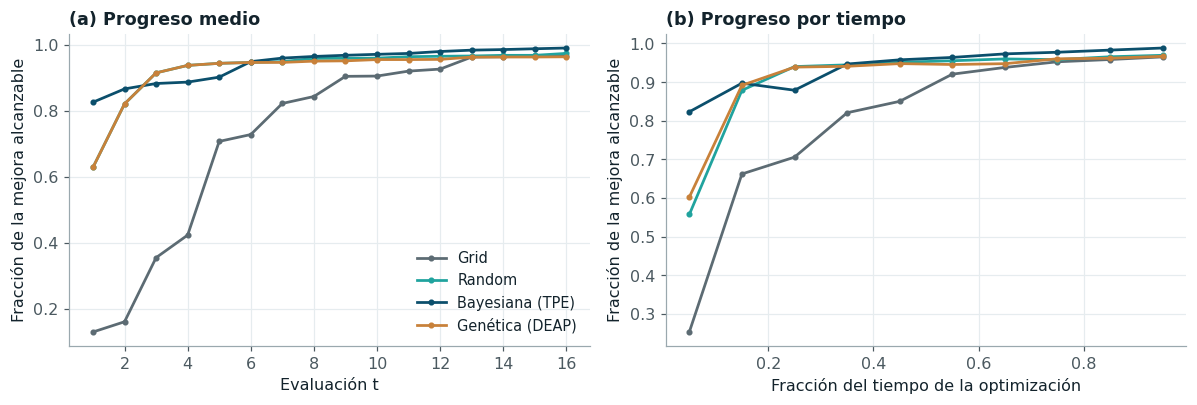

In [4]:
h2 = h.copy()
clave = ["modelo", "balanceo", "pliegue"]
techo = h2.groupby(clave).puntaje.max().rename("techo")
piso = h2[h2["eval"] == 1].groupby(clave).puntaje.min().rename("piso")
h2 = h2.join(techo, on=clave).join(piso, on=clave)
h2["progreso"] = ((h2.mejor - h2.piso) / (h2.techo - h2.piso).replace(0, np.nan)).clip(0, 1).fillna(1)
curva = h2.groupby(["optimizador", "eval"]).progreso.mean().unstack(0)[OPT]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for o in OPT:
    axs[0].plot(curva.index, curva[o], "-o", ms=3, color=COL[o], label=NOMBRES_OPT[o])
axs[0].set(xlabel="Evaluación t", ylabel="Fracción de la mejora alcanzable", title="(a) Progreso medio")
axs[0].legend()
# Calidad por unidad de tiempo: mejor valor alcanzado en función del tiempo acumulado (normalizado por problema)
h2["t_rel"] = h2.t_acum / h2.groupby(clave + ["optimizador"]).t_acum.transform("max")
for o in OPT:
    d = h2[h2.optimizador == o]
    bins = np.linspace(0, 1, 11)
    m = d.groupby(pd.cut(d.t_rel, bins)).progreso.mean()
    axs[1].plot((bins[:-1] + bins[1:]) / 2, m.values, "-o", ms=3, color=COL[o], label=NOMBRES_OPT[o])
axs[1].set(xlabel="Fracción del tiempo de la optimización", ylabel="Fracción de la mejora alcanzable", title="(b) Progreso por tiempo")
plt.tight_layout(); plt.show()
area = curva.mean()
for o in OPT:
    glue(f"auc_any_{o}", float(area[o]), display=False)
    glue(f"prog8_{o}", float(curva.loc[8, o]), display=False)
    glue(f"fin_{o}", float(curva.loc[16, o]), display=False)
# Evidencia cuantitativa: progreso a mitad de presupuesto (t = 8), pareado por problema
p8 = h2[h2["eval"] == 8].pivot_table(index=clave, columns="optimizador", values="progreso")
filas = []
for a, b in (("bayes", "grid"), ("bayes", "random"), ("genetico", "grid"), ("genetico", "random"), ("bayes", "genetico")):
    w = wilcoxon(p8[a], p8[b], alternative="greater", zero_method="zsplit")
    filas.append({"comparación": f"{NOMBRES_OPT[a]} > {NOMBRES_OPT[b]}", "Δ progreso medio en t = 8": (p8[a] - p8[b]).mean(),
                  "p (Wilcoxon, unilateral)": w.pvalue, "δ de Cliff": delta_cliff(p8[a], p8[b])})
ef = pd.DataFrame(filas); ef["p (Holm)"] = holm(ef["p (Wilcoxon, unilateral)"].values)

In [5]:
ef.round(4)

,comparación,Δ progreso medio en t = 8,"p (Wilcoxon, unilateral)",δ de Cliff,p (Holm)
0,Bayesiana (TPE) > Grid,0.1215,0.0000,0.5769,0.0000
1,Bayesiana (TPE) > Random,0.0059,0.0293,0.0851,0.0587
2,Genética (DEAP) > Grid,0.1072,0.0000,0.4939,0.0000
3,Genética (DEAP) > Random,-0.0083,0.5898,-0.0337,0.5898
4,Bayesiana (TPE) > Genética (DEAP),0.0142,0.0004,0.1203,0.0012


La guía pide demostrar con evidencia cuantitativa, y no solo visual, que los métodos bayesiano y
genético pueden ser más eficientes que la rejilla y la búsqueda aleatoria. La evidencia es
mixta. Frente a la rejilla, la ventaja es clara y grande: a mitad de presupuesto (t = 8), TPE ha
recorrido el {glue:text}`prog8_bayes:.1%` de la mejora alcanzable y el algoritmo genético el
{glue:text}`prog8_genetico:.1%`, frente al {glue:text}`prog8_grid:.1%` de la rejilla, con
diferencias significativas tras la corrección de Holm y tamaños de efecto de Cliff grandes
(0,58 y 0,49). El área bajo la curva anytime, que resume la calidad alcanzada por unidad de
presupuesto, ordena los métodos de la misma forma: {glue:text}`auc_any_bayes:.3f` para TPE,
{glue:text}`auc_any_random:.3f` para la búsqueda aleatoria, {glue:text}`auc_any_genetico:.3f`
para el genético y {glue:text}`auc_any_grid:.3f` para la rejilla. La rejilla pierde porque
recorre el espacio en un orden sistemático y gasta sus primeras evaluaciones en un extremo del
dominio; además, con varios parámetros asigna pocos niveles a cada uno, la debilidad descrita
por Bergstra y Bengio {cite}`bergstra2012`.

Frente a la búsqueda aleatoria, en cambio, la ventaja de TPE es pequeña (0,6 puntos de progreso
a mitad de presupuesto, δ de Cliff de 0,09) y no sobrevive a la corrección de Holm, y el
algoritmo genético no la supera. La explicación está en el presupuesto: TPE dedica sus seis
primeras evaluaciones, el 37 % del total, a muestreo aleatorio para construir las densidades
$\ell(x)$ y $g(x)$, y solo explota el modelo sustituto en las diez restantes; el genético, con una
población de seis y dos generaciones, apenas alcanza a recombinar. Con presupuestos mayores o
espacios de más dimensiones, donde la búsqueda aleatoria pierde cobertura, la ventaja teórica
de los métodos guiados por el historial debería ampliarse; en este problema, su eficiencia
superior se demuestra con claridad frente a la rejilla y solo de forma marginal frente al
muestreo aleatorio. La forma de las curvas ({numref}`fig-anytime`) confirma esa lectura: la
búsqueda aleatoria y el genético coinciden en las primeras seis evaluaciones porque ambos parten
de configuraciones extraídas con la misma semilla, y a partir de la sexta, cuando TPE empieza a
explotar su modelo sustituto, su curva se separa de las demás y termina en
{glue:text}`fin_bayes:.1%` de la mejora alcanzable, frente a {glue:text}`fin_random:.1%` de la
búsqueda aleatoria.

## Diversidad genética y convergencia prematura

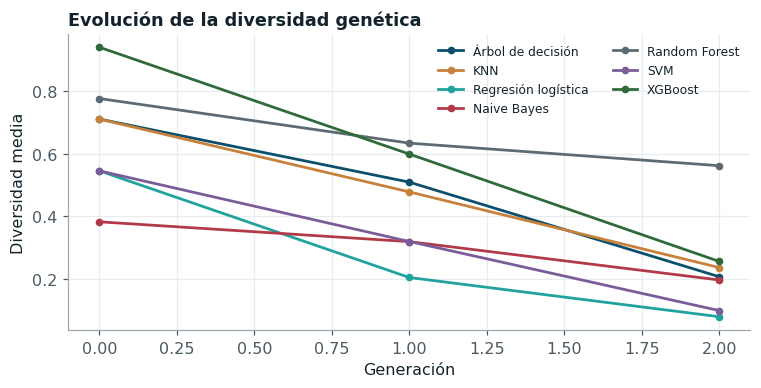

In [6]:
ga = h[(h.optimizador == "genetico")].dropna(subset=["generacion"])
div = ga.groupby(["modelo", "generacion"]).diversidad.mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, m in enumerate(div.columns):
    ax.plot(div.index, div[m], "-o", ms=4, label=NOMBRES_MODELO[m], color=(estilo.COLORES + ["#7a5c99", "#2f6b3a"])[i])
ax.set(xlabel="Generación", ylabel="Diversidad media", title="Evolución de la diversidad genética"); ax.legend(fontsize=8, ncol=2)
plt.show()
red = (1 - div.iloc[-1] / div.iloc[0]).mean()
glue("red_div", float(red), display=False)

La diversidad de la población cae en promedio un {glue:text}`red_div:.0%` entre la población
inicial y la última generación. Es una convergencia rápida, esperable con una población de seis
individuos, selección por torneo de tamaño tres y elitismo, que en dos generaciones concentran
la población alrededor de los mejores individuos. En un problema de optimización general sería
una señal de convergencia prematura; aquí no resultó perjudicial, porque la PR-AUC externa del
genético es igual a la de los demás métodos, pero indica que el algoritmo funcionó más como un
explotador local alrededor de la mejor configuración inicial que como un explorador del
espacio. Una población mayor o una probabilidad de mutación más alta preservarían la diversidad
a costa de presupuesto.

## Optimización multifidelidad

In [7]:
mf = pd.read_csv(RESULTADOS / "computacional" / "multifidelidad.csv")
for m in mf.modelo.unique():
    a = mf[(mf.modelo == m) & mf.metodo.str.startswith("halving")].iloc[0]
    b = mf[(mf.modelo == m) & ~mf.metodo.str.startswith("halving")].iloc[0]
    glue(f"mf_ahorro_{m}", float(1 - a.tiempo_s / b.tiempo_s), display=False)
    glue(f"mf_dif_{m}", float(a.pr_auc_bloque_externo - b.pr_auc_bloque_externo), display=False)
mf.round(4)

,modelo,metodo,tiempo_s,arboles_ajustados,mejor_interno,pr_auc_bloque_externo,rondas
0,xgboost,halving (factor 3),13.3558,7128,0.9056,0.4978,4
1,xgboost,aleatoria (fidelidad completa),29.0611,48600,0.9055,0.4990,1
2,random_forest,halving (factor 3),28.7044,2916,0.9221,0.5901,4
3,random_forest,aleatoria (fidelidad completa),142.1162,19683,0.9237,0.5843,1


*Successive Halving* {cite}`jamieson2016` evalúa 27 configuraciones con un presupuesto parcial
(1/27 del número máximo de árboles), conserva el tercio mejor y triplica su presupuesto en cada
ronda hasta que queda una con el presupuesto completo. La métrica de fidelidad es la misma
PR-AUC de la validación interna, calculada con modelos de menos árboles; el factor de reducción
de 3 equilibra el número de rondas (cuatro) con el riesgo de eliminar demasiado pronto una
configuración que solo destaca con muchos árboles, riesgo que crece con factores mayores. En
XGBoost el método ahorra el {glue:text}`mf_ahorro_xgboost:.0%` del tiempo frente a la búsqueda
aleatoria sobre los mismos 27 candidatos con fidelidad completa, con una diferencia de
{glue:text}`mf_dif_xgboost:+.4f` en la PR-AUC del bloque externo; en Random Forest ahorra el
{glue:text}`mf_ahorro_random_forest:.0%`, con una diferencia de
{glue:text}`mf_dif_random_forest:+.4f`.

El ahorro proviene de que la mayoría de las configuraciones se descartan tras evaluarse con
pocos árboles: en Random Forest se ajustaron 2.916 árboles en total frente a 19.683 de la búsqueda
completa, y en XGBoost 7.128 frente a 48.600. La calidad de la configuración elegida no se
resiente, porque en ambos modelos el orden relativo de las configuraciones con pocos árboles
anticipa bien el orden con el presupuesto completo: los hiperparámetros que controlan la
complejidad de cada árbol (profundidad, tamaño mínimo de hoja, fracción de variables) determinan
la calidad desde las primeras rondas. El riesgo opuesto, eliminar una configuración con tasa de
aprendizaje baja que solo destaca con muchos árboles, es la razón para usar como recurso el
número de árboles y no la tasa, y para no superar un factor de reducción de 3. El ahorro
liberado podría reasignarse a evaluar más candidatos con el mismo tiempo total.